# Full interaction (Heisenberg + RKKY)

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables

using LinearAlgebra: norm
using HDF5
using CSV
using DataFrames

using Makie

## Analyse data

In [2]:
function collect_from_h5(ar, name)
    T_range = ar["params/T_range"][]
    return [ar["/T$(T)/$(name)"][] for T in T_range if "T$(T)" in keys(ar)] 
end

function make_observables_df(ar)
    params = read(ar, "params")
    L = params["L"][]
    T_range = [T for T in params["T_range"] if "T$(T)" in keys(ar)]
    β_range = 1.0 ./ T_range

    df = DataFrame("T" => T_range)

    metadata!(df, "L", L, style=:note)
    metadata!(df, "V", params["V"], style=:note)
    metadata!(df, "lambda", params["lambda"], style=:note)
    if "rkky_range_cutoff" in keys(params)
        metadata!(df, "rkky_range_cutoff", params["rkky_range_cutoff"], style=:note)
    end
    
    # Energy
    insertcols!(df,
        "E_min" => collect_from_h5(ar, "min_energy") / L^2,
        "E_avg" => collect_from_h5(ar, "avg_energy") / L^2,
        "E_var" => collect_from_h5(ar, "var_energy") / L^2,
        "E_err" => collect_from_h5(ar, "err_energy") / L^2
    )
    colmetadata!(df, :E_avg, "plot", true, style=:note)
    colmetadata!(df, :E_avg, "errors", :E_err, style=:note)
    colmetadata!(df, :E_avg, "ylabel", L"$\langle E\rangle$, per atom", style=:note)
    colmetadata!(df, :E_min, "plot", false, style=:note)
    colmetadata!(df, :E_var, "plot", false, style=:note)
    colmetadata!(df, :E_err, "plot", false, style=:note)
    
    # Specific heat
    insertcols!(df, "cV" => collect_from_h5(ar, "specific_heat") / L^2)
    colmetadata!(df, :cV, "plot", true, style=:note)
    colmetadata!(df, :cV, "ylabel", L"$c_V$, per atom", style=:note)
    
    # Average chirality
    insertcols!(df,
        "chi_avg" => collect_from_h5(ar, "avg_chirality"),
        "chi_var" => collect_from_h5(ar, "var_chirality"),
        "chi_err" => collect_from_h5(ar, "err_chirality"),
    )
    colmetadata!(df, :chi_avg, "plot", true, style=:note)
    colmetadata!(df, :chi_avg, "errors", :chi_err, style=:note)
    colmetadata!(df, :chi_avg, "ylabel", L"$\langle\chi\rangle$", style=:note)
    colmetadata!(df, :chi_var, "plot", false, style=:note)
    colmetadata!(df, :chi_err, "plot", false, style=:note)
    
    # Chirality susceptibility
    insertcols!(df, "susc_chi" => collect_from_h5(ar, "susc_chirality") / L^2)
    colmetadata!(df, :susc_chi, "plot", true, style=:note)
    colmetadata!(df, :susc_chi, "ylabel", L"$\chi_c = \langle(\delta\chi)^2\rangle / T$, per atom", style=:note)
    
    # Chirality Binder cumulant
    insertcols!(df, "binder_chi" => collect_from_h5(ar, "binder_chirality"))
    colmetadata!(df, :binder_chi, "plot", true, style=:note)
    colmetadata!(df, :binder_chi, "ylabel", L"$g_c$", style=:note)
        
    # Chirality correlation length
    insertcols!(df, "corr_length_chi" => abs.(collect_from_h5(ar, "corr_length_chirality")))
    colmetadata!(df, :corr_length_chi, "plot", true, style=:note)
    colmetadata!(df, :corr_length_chi, "ylabel", L"$\xi_c$", style=:note)
    colmetadata!(df, :corr_length_chi, "yscale", log10, style=:note)
        
    # Average magnetization at K-point
    insertcols!(df,
        "m_abs_at_K_avg" => norm.(collect_from_h5(ar, "avg_spin_K")),
        "m_abs_at_K_var" => collect_from_h5(ar, "var_spin_K"),
        "m_abs_at_K_err" => collect_from_h5(ar, "err_spin_K")
    )
    colmetadata!(df, :m_abs_at_K_avg, "plot", true, style=:note)
    colmetadata!(df, :m_abs_at_K_avg, "errors", :m_abs_at_K_err, style=:note)
    colmetadata!(df, :m_abs_at_K_avg, "ylabel", L"$|\langle\mathbf{m}(\mathbf{K})\rangle|$", style=:note)
    colmetadata!(df, :m_abs_at_K_var, "plot", false, style=:note)
    colmetadata!(df, :m_abs_at_K_err, "plot", false, style=:note)
   
    # Magnetization at K-point: susceptibility
    insertcols!(df, "susc_spin_K" => collect_from_h5(ar, "susc_spin_K") / L^2)
    colmetadata!(df, :susc_spin_K, "plot", true, style=:note)
    colmetadata!(df, :susc_spin_K, "ylabel", L"$\chi_s = \langle(\delta\vec{m}(\vec{K}))^2\rangle / T$", style=:note)
    
    # Magnetization at K-point: Binder cumulant
    insertcols!(df, "binder_spin_K" => collect_from_h5(ar, "binder_spin_K"))
    colmetadata!(df, :binder_spin_K, "plot", true, style=:note)
    colmetadata!(df, :binder_spin_K, "ylabel", L"$g_s$", style=:note)
    
    # Magnetization at K-point: Correlation length
    insertcols!(df, "corr_length_spin_K" => abs.(collect_from_h5(ar, "corr_length_spin_K")))
    colmetadata!(df, :corr_length_spin_K, "plot", true, style=:note)
    colmetadata!(df, :corr_length_spin_K, "ylabel", L"$\xi_s$", style=:note)
    colmetadata!(df, :corr_length_spin_K, "yscale", log10, style=:note)

    # Covariance chirality -- magnetization at K-point
    insertcols!(df, "cov_chirality_spin_K" => norm.(collect_from_h5(ar, "cov_chirality_spin_K")))
    colmetadata!(df, :cov_chirality_spin_K, "plot", true, style=:note)
    colmetadata!(df, :cov_chirality_spin_K, "ylabel", L"$|\langle\delta\chi\delta\vec{m}(\vec{K})\rangle|$", style=:note)
    
    return df
end

make_observables_df (generic function with 1 method)

## Plot results

In [3]:
function plot_observables(dfs::Vector{DataFrame}; figsize=(1000, 2000), pdfname)
    all_cols = union(keys.(eachcol.(dfs))...)
    plot_col = name -> (name != :T) && any([colmetadata(df, name, "plot") for df in dfs])    
    nplots = count(plot_col, all_cols)
    
    T = dfs[1].T
    
    fig = Figure(size=figsize)
    plt_i = 1
    for name in all_cols
        !plot_col(name) && continue
        ax = Axis(fig[plt_i, 1],
                  xlabel = (plt_i == nplots) ? L"$T/J$" : "",
                  ylabel = colmetadata(dfs[1], name, "ylabel"),
                  yscale = colmetadata(dfs[1], name, "yscale", identity),
                  xticklabelsvisible = (plt_i == nplots),
                  xticksvisible = (plt_i == nplots),
                  xticks = LinearTicks(20))

        ymin = Inf
        ymax = -Inf
        for df in dfs
            L = metadata(df, "L")
            V = metadata(df, "V")
            lambda = metadata(df, "lambda")
            R = metadata(df, "rkky_range_cutoff")
            label = L"$V=%$(V),\ k_F a_0 = %$(lambda),\ R_V=%$(R),\ L=%$(L)$"

            data = df[!, name]
            
            lines!(ax, df.T, data, linewidth=1.0, label=label)
            if "errors" in keys(colmetadata(df, name))
                errors = df[!, colmetadata(df, name, "errors")]
                errorbars!(ax, df.T, data, errors, linewidth=1.0)
            end

            ymin = min(ymin, minimum(data))
            ymax = max(ymax, maximum(data))
        end
        xlims!(first(dfs[1].T), last(dfs[1].T))
        Δy = ymax - ymin
        ylims!(ymin, ymax + 0.1Δy)

        Legend(fig[plt_i, 2], ax)
        plt_i += 1
    end

    # General plot setup
    rowgap!(fig.layout, 0)
    save(pdfname, fig)
    fig
end

plot_observables (generic function with 1 method)

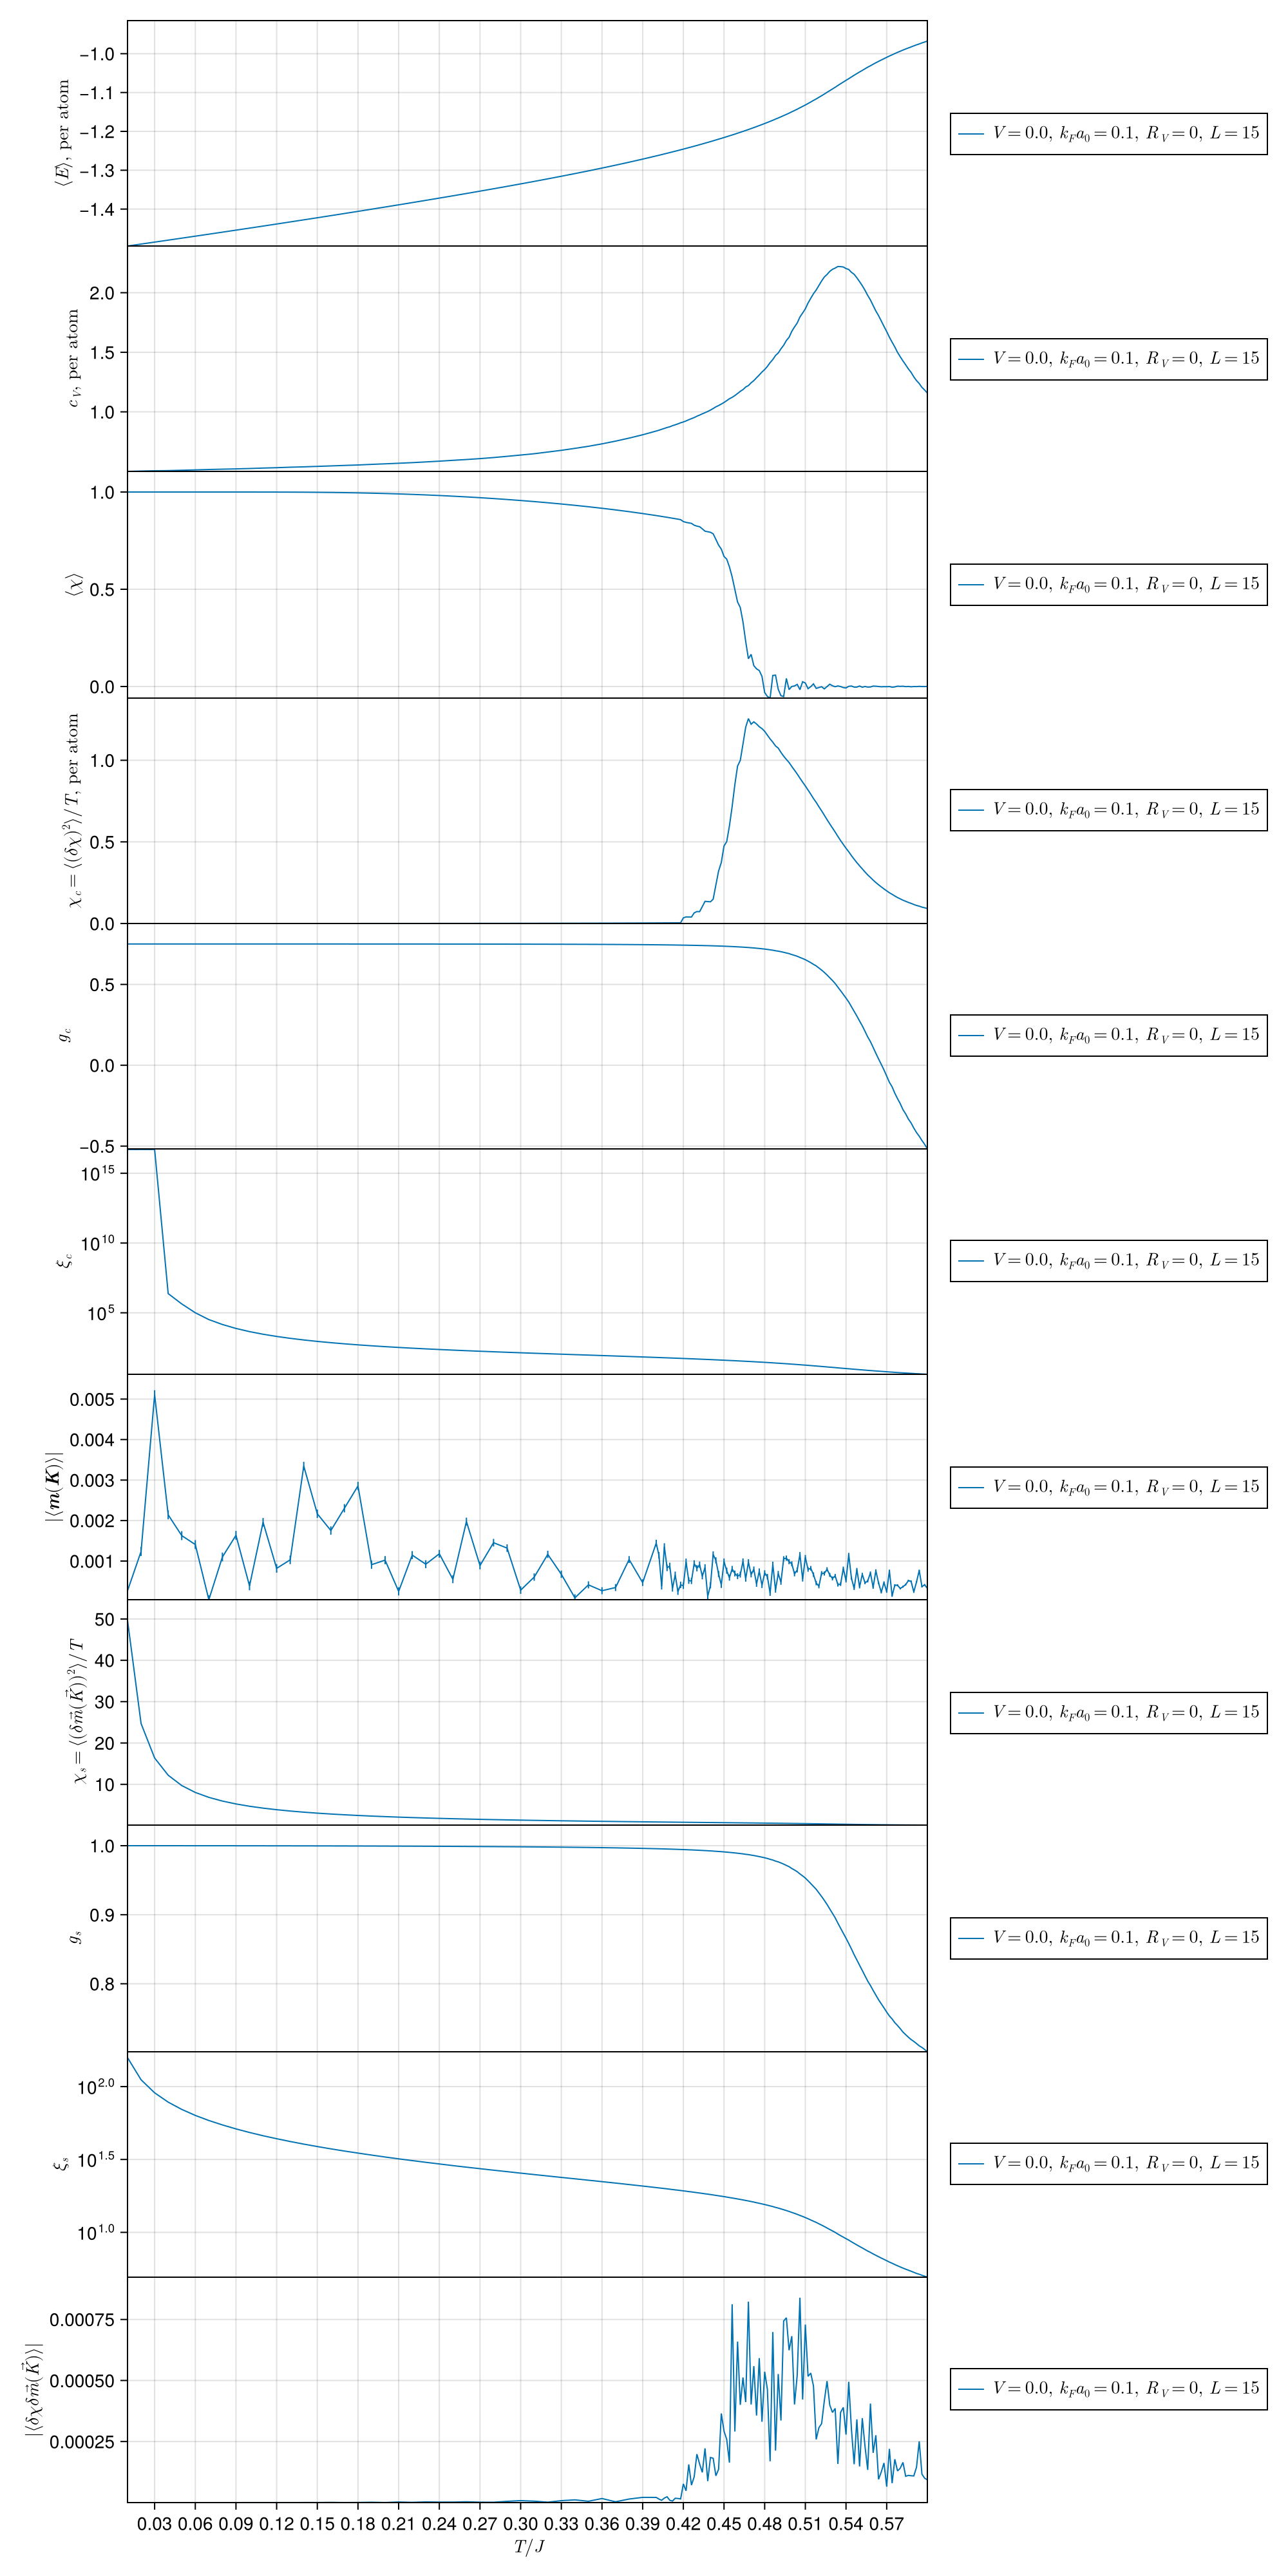

In [24]:
df_xy_15 = make_observables_df(h5open("../../RKKY_temperature_scan/XY_T_scan_L15.old.h5", "r"));
plot_observables([df_xy_15], pdfname="XY_T_scan_L15.pdf")

## Export results

In [25]:
function export_observables(df::DataFrame)
    L = metadata(df, "L")
    V = metadata(df, "V")
    lambda = metadata(df, "lambda")
    CSV.write("RKKY_T_scan_V$(V)_lambda$(lambda)_L$(L).dat", df, delim="    ");
end

export_observables (generic function with 1 method)

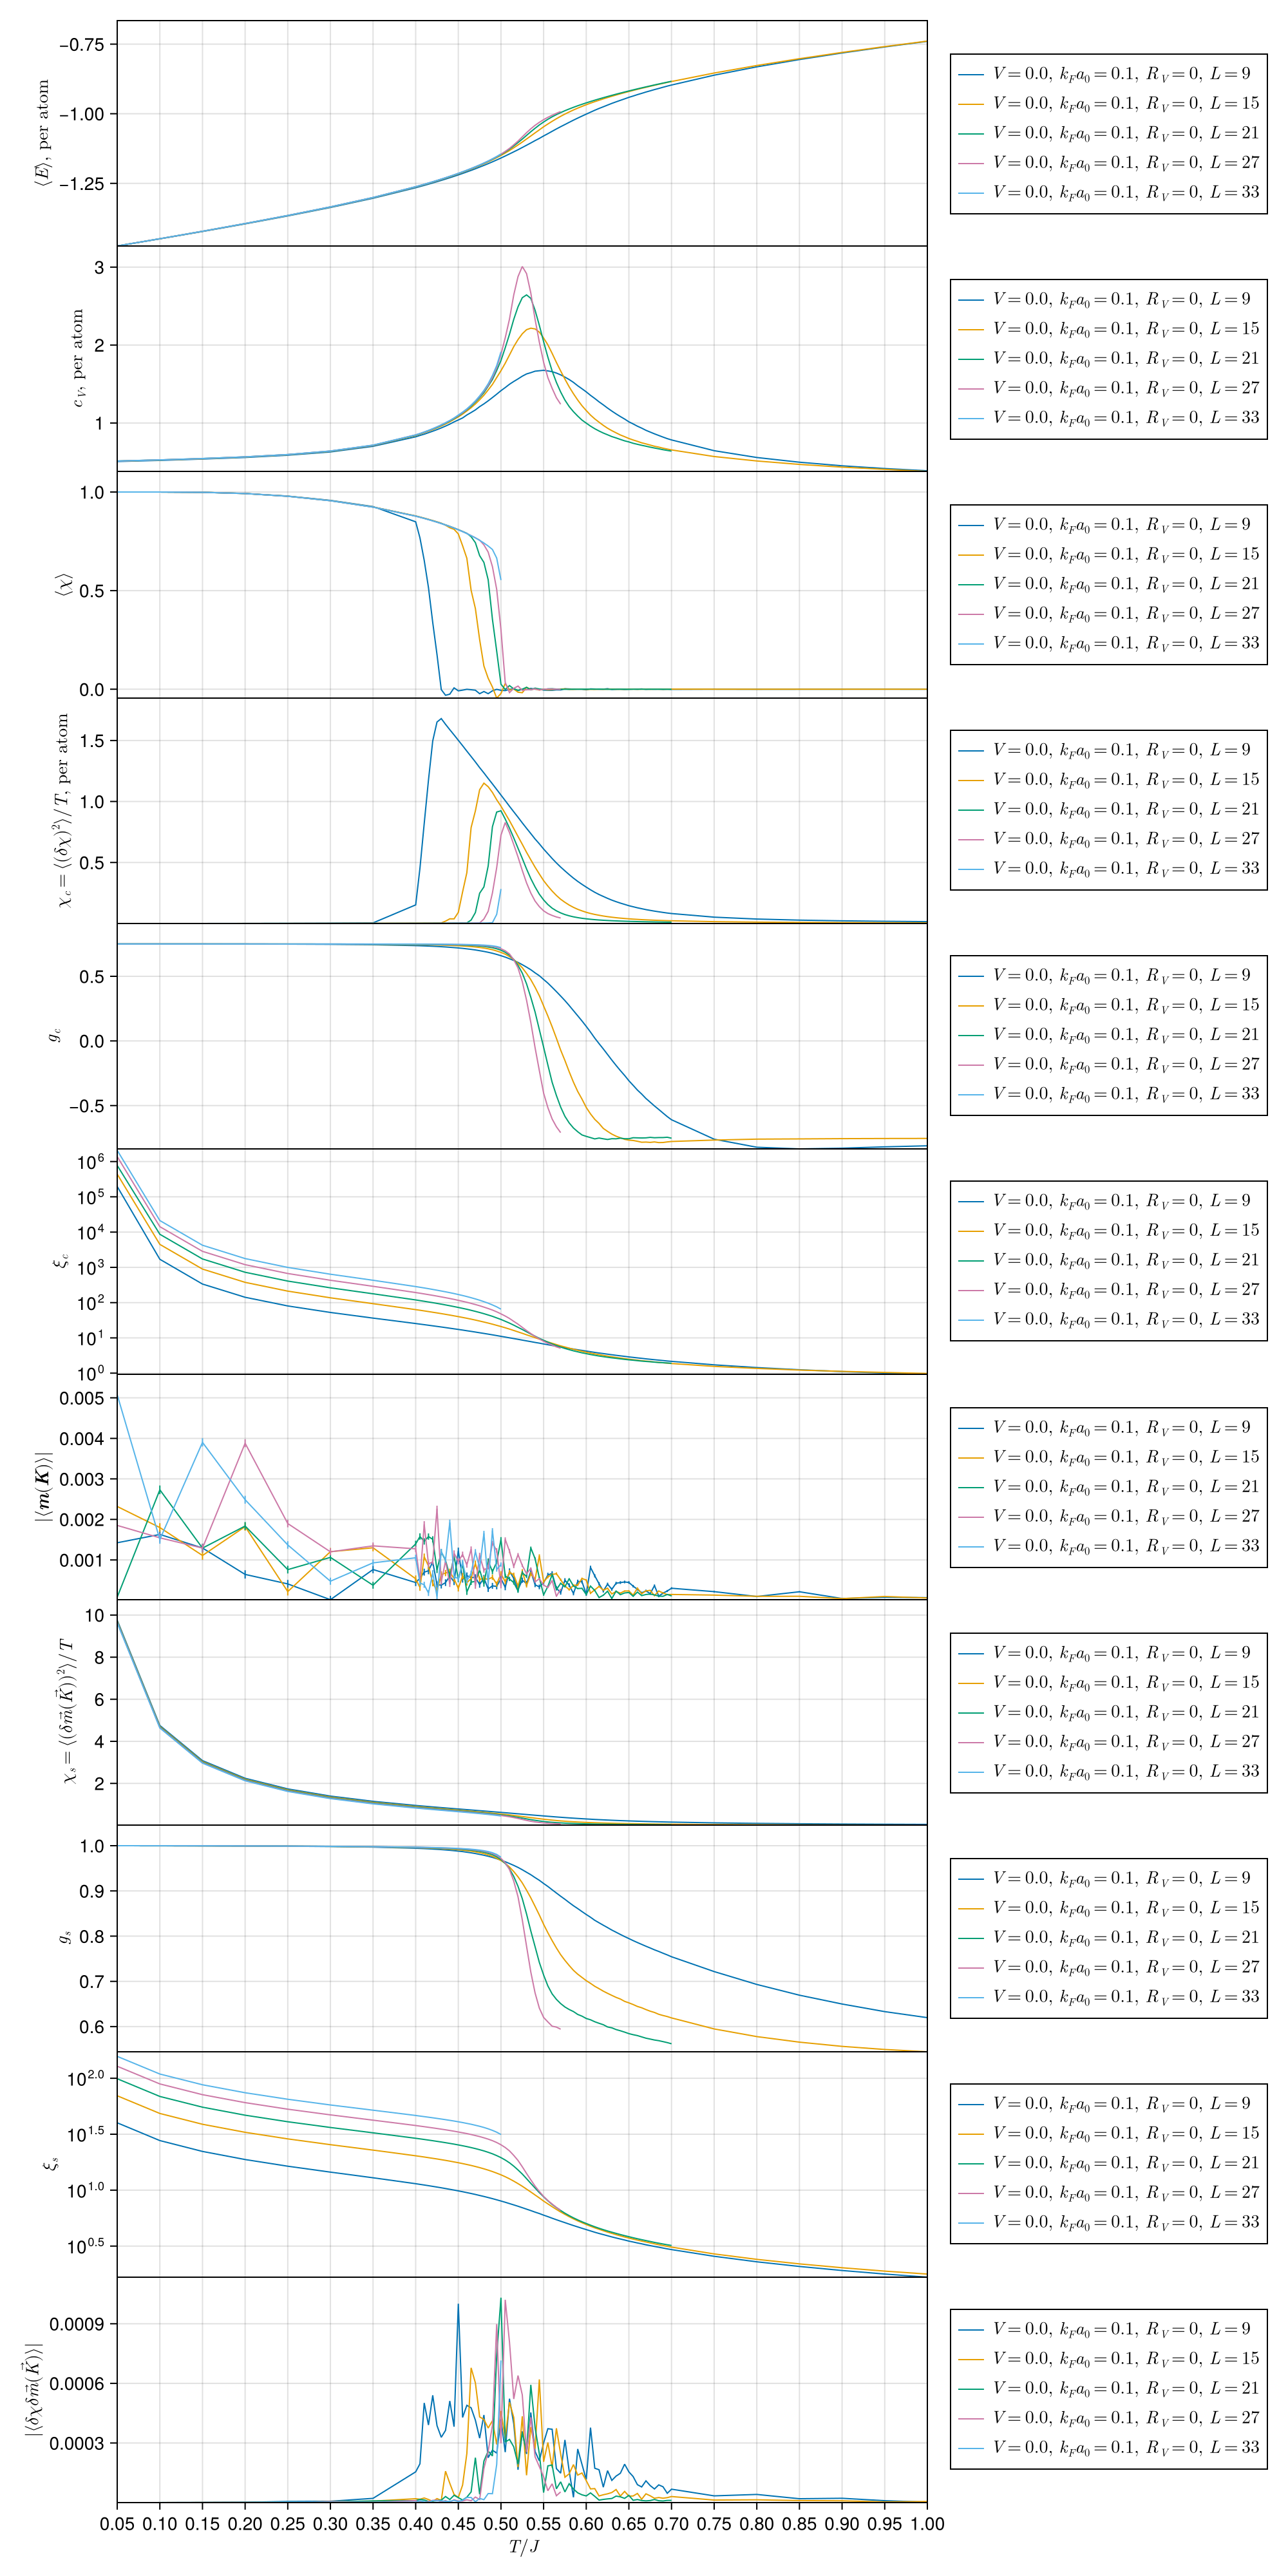

In [5]:
dfs_xy = [make_observables_df(h5open("../../RKKY_temperature_scan/2025.07.23/XY_T_scan_L$(L).h5", "r")) for L in [9, 15, 21, 27, 33]];
plot_observables(dfs_xy, pdfname="XY_T_scan.pdf")

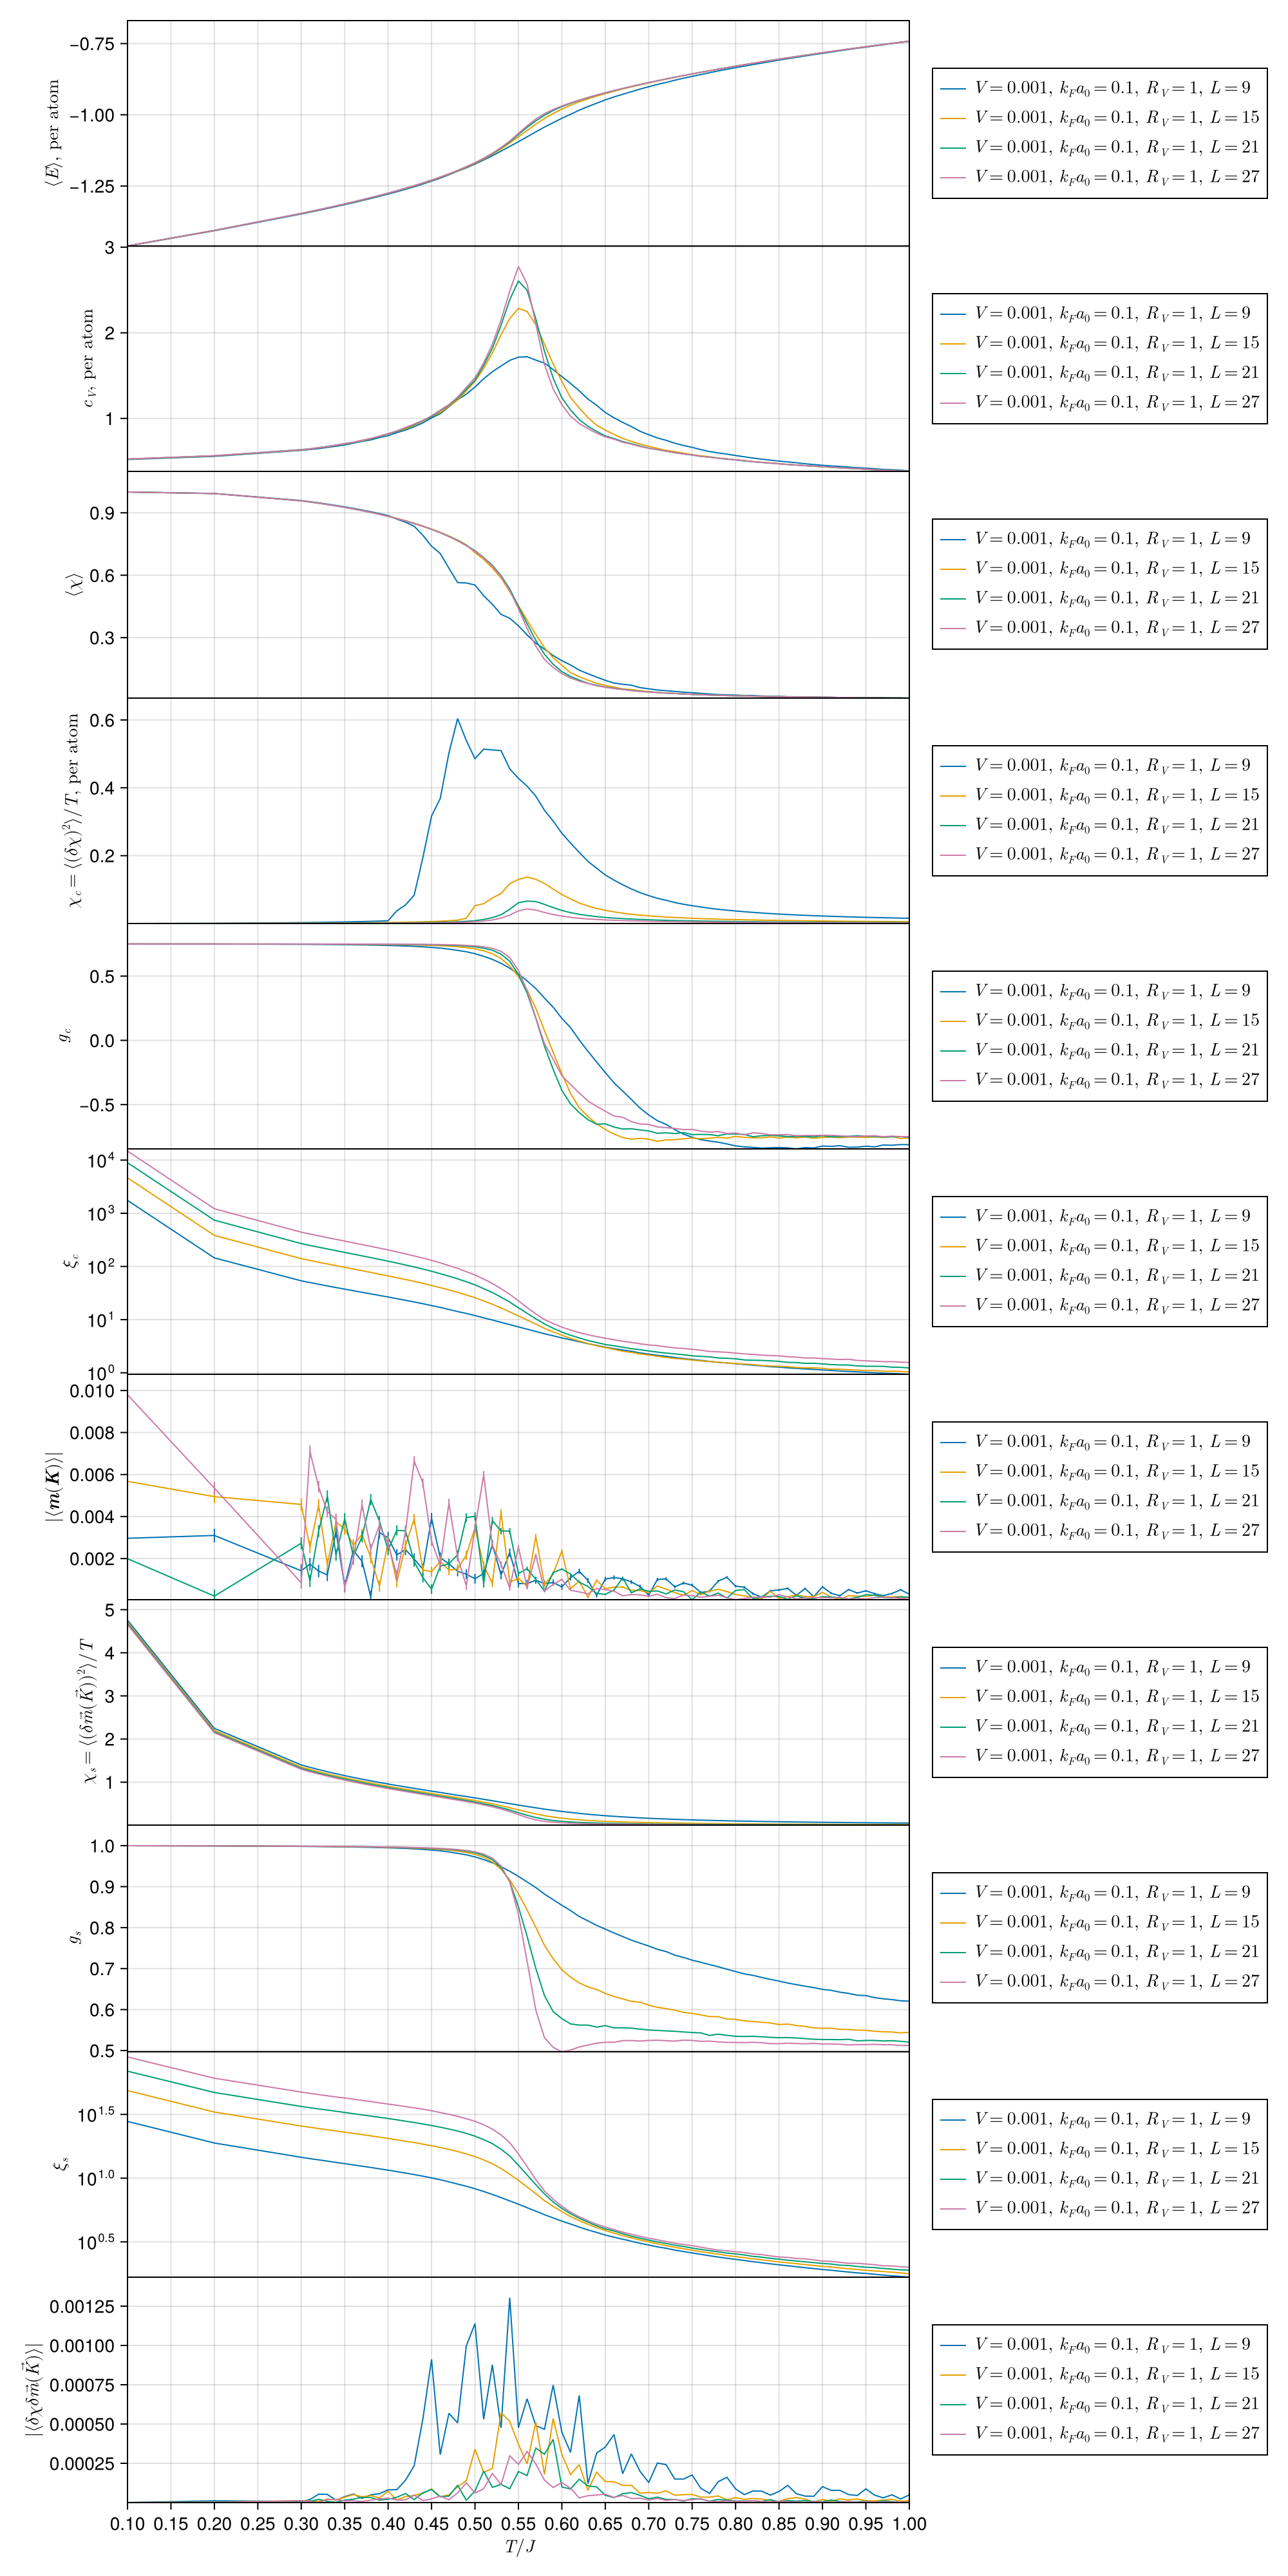

In [6]:
#dfs_rkky = [make_observables_df(h5open("../../RKKY_temperature_scan/2025.07.22/RKKY_T_scan_V0.001_lambda0.1_R1_L$(L).h5", "r")) for L in [9, 15, 21, 27, 33]];
dfs_rkky = [make_observables_df(h5open("../../RKKY_temperature_scan/2025.07.23/RKKY_T_scan_V0.001_lambda0.1_R1_L$(L).h5", "r")) for L in [9, 15, 21, 27]];
plot_observables(dfs_rkky, pdfname="RKKY_T_scan.pdf")